#   Importación del dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.dataset import load_dataset

Para configurar el estilo gráfico

In [2]:
sns.set_theme(
    style="whitegrid",
    palette="pastel",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 150

Importamos el dataset

In [3]:
df = load_dataset()
assert df.shape == (48_842, 15)

X = df.drop(columns="income").copy()
y = df[["income"]].copy()

display(df.head(10))

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


Para ver sus dimensiones y análizar sus estadisticas descriptivas

In [4]:
print("Dataset shape:", df.shape)
print("Input features:", X.shape[1])
print("Number of samples:", len(df))

df.info()
display(df.describe())

Dataset shape: (48842, 15)
Input features: 14
Number of samples: 48842
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


Inspección de clases

In [5]:
print(y.iloc[:, 0].value_counts(dropna=False))
fig = px.histogram(
    df,
    x="income",
    color="income",
    title="Income Class Distribution",
    text_auto=True,
    color_discrete_sequence=px.colors.qualitative.Pastel
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Income Class",
    yaxis_title="Number of Samples",
    showlegend=False
)

fig.show()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


La clase ≤50K reúne 37.155 registros (76,07 %) y >50K reúne 11.687 (23,93 %). Este desbalanceo hace que accuracy por sí sola sea insuficiente: predecir siempre ≤50K ya alcanzaría 76,07 %. En la comparación de redes revisaremos especialmente precision, recall y F1 de >50K.

### ¿Cómo se distribuyen las variables?

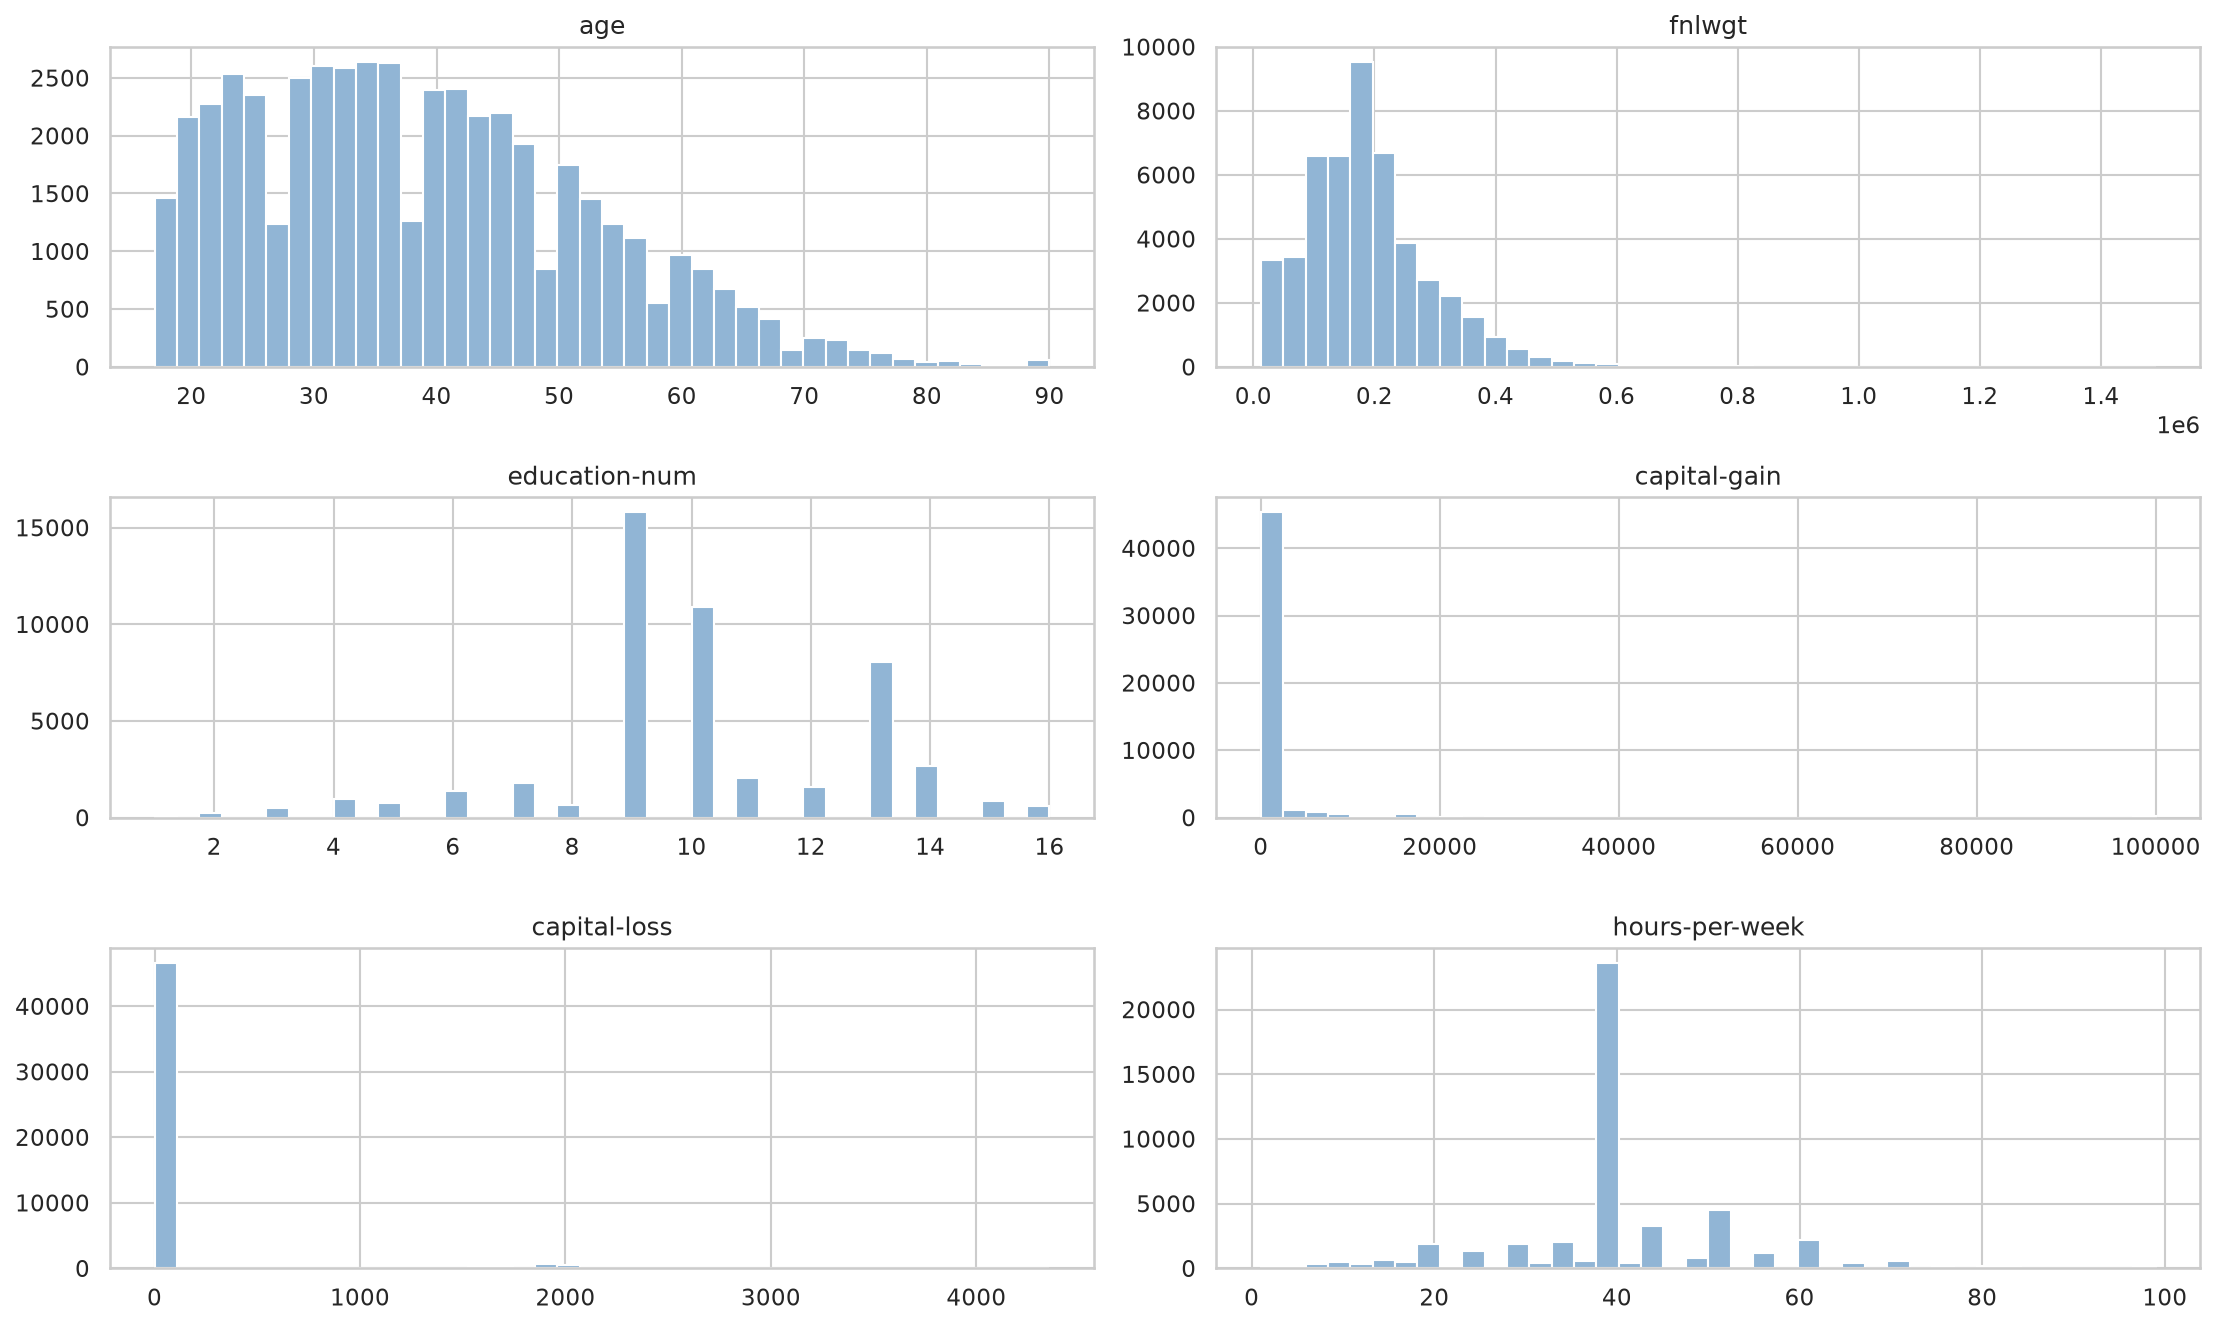

In [6]:
numeric_columns = df.select_dtypes(
    include="number"
).columns

df[numeric_columns].hist(
    bins=40,
    figsize=(15, 9),
    color="#91B5D5",
    edgecolor="white"
)

plt.tight_layout()
plt.show()

Ver el comportamiento de cada variable nos sirve para seleccionar el mejor método de normalización.
De las anteriores podemos concluir que:

- **Age:** Tiene una asimetría positiva porque la mayor cantidad de personas se concentra entre los 20 y 50 años

- **fnlwgt:** Asimetría positiva dado que la mayoria de los pesos se concentran debajo de 400000.

- **education-num:** Tiene varios picos y hay que considerar que es una variable ordinal.

- **capital-gain:** Alta concentración en cero porque la mayoría de las personas no registra ganancias de capital

- **capital-loss:** AL igual que la anterior tiene alta concentración en cero porque la mayoria de las personas no presentan pérdidas de capital.

- **hours-per-week:** Hay un pico en las 40 horas semanales, pero el resto se comporta más o menos similar.

### ¿Qué variables están correlacionadas?

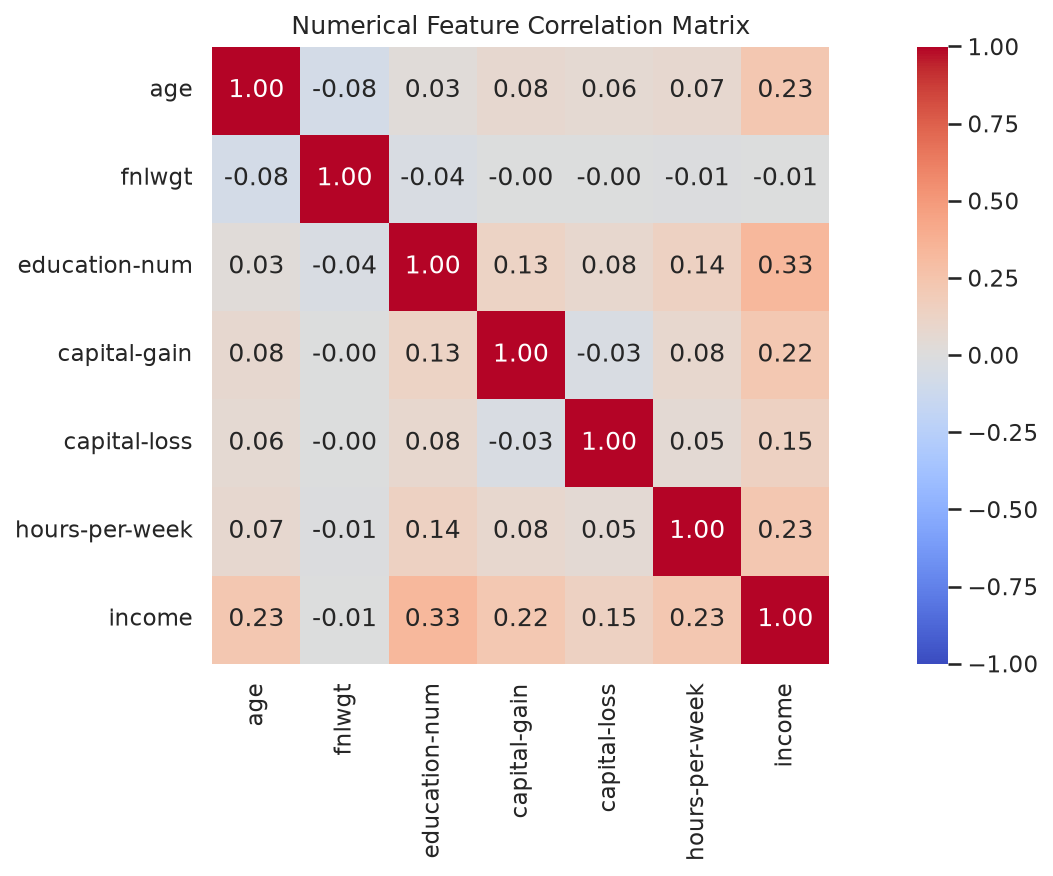

In [7]:
df_corr = df.copy()

df_corr["income"] = df_corr["income"].map({
    "<=50K": 0,
    ">50K": 1
})

correlation_matrix = df_corr.select_dtypes(
    include="number"
).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.show()

La correlación de Pearson con los ingresos es mayor para `education-num` (0,333), seguida de la edad (0,230) y las horas de trabajo semanales (0,228). Estas variables aportan señales útiles para la clasificación.

Por otra parte, `fnlwgt` presenta una correlación prácticamente nula con los ingresos (−0,006), lo que respalda su exclusión junto con su naturaleza de peso censal.

No se observan correlaciones lineales fuertes entre las variables numéricas analizadas. Esto no descarta relaciones no lineales que puedan aprovechar las redes multicapa.

### Identificación de valores faltantes

In [8]:
missing = df.isna().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

fig = px.bar(
    x=missing.index,
    y=missing.values,
    text=missing.values,
    title="Missing Values by Feature"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Feature",
    yaxis_title="Missing values"
)

fig.show()

Los archivos originales contienen valores faltantes en `occupation` (2.809), `workclass` (2.799) y `native-country` (857). `load_dataset()` interpreta los marcadores `?` como valores ausentes, por lo que ahora se contabilizan en toda la población. Se reemplazarán por `Unknown` durante el preprocesamiento para conservar los 48.842 registros y la información disponible en sus demás variables.

### Datos atípicos

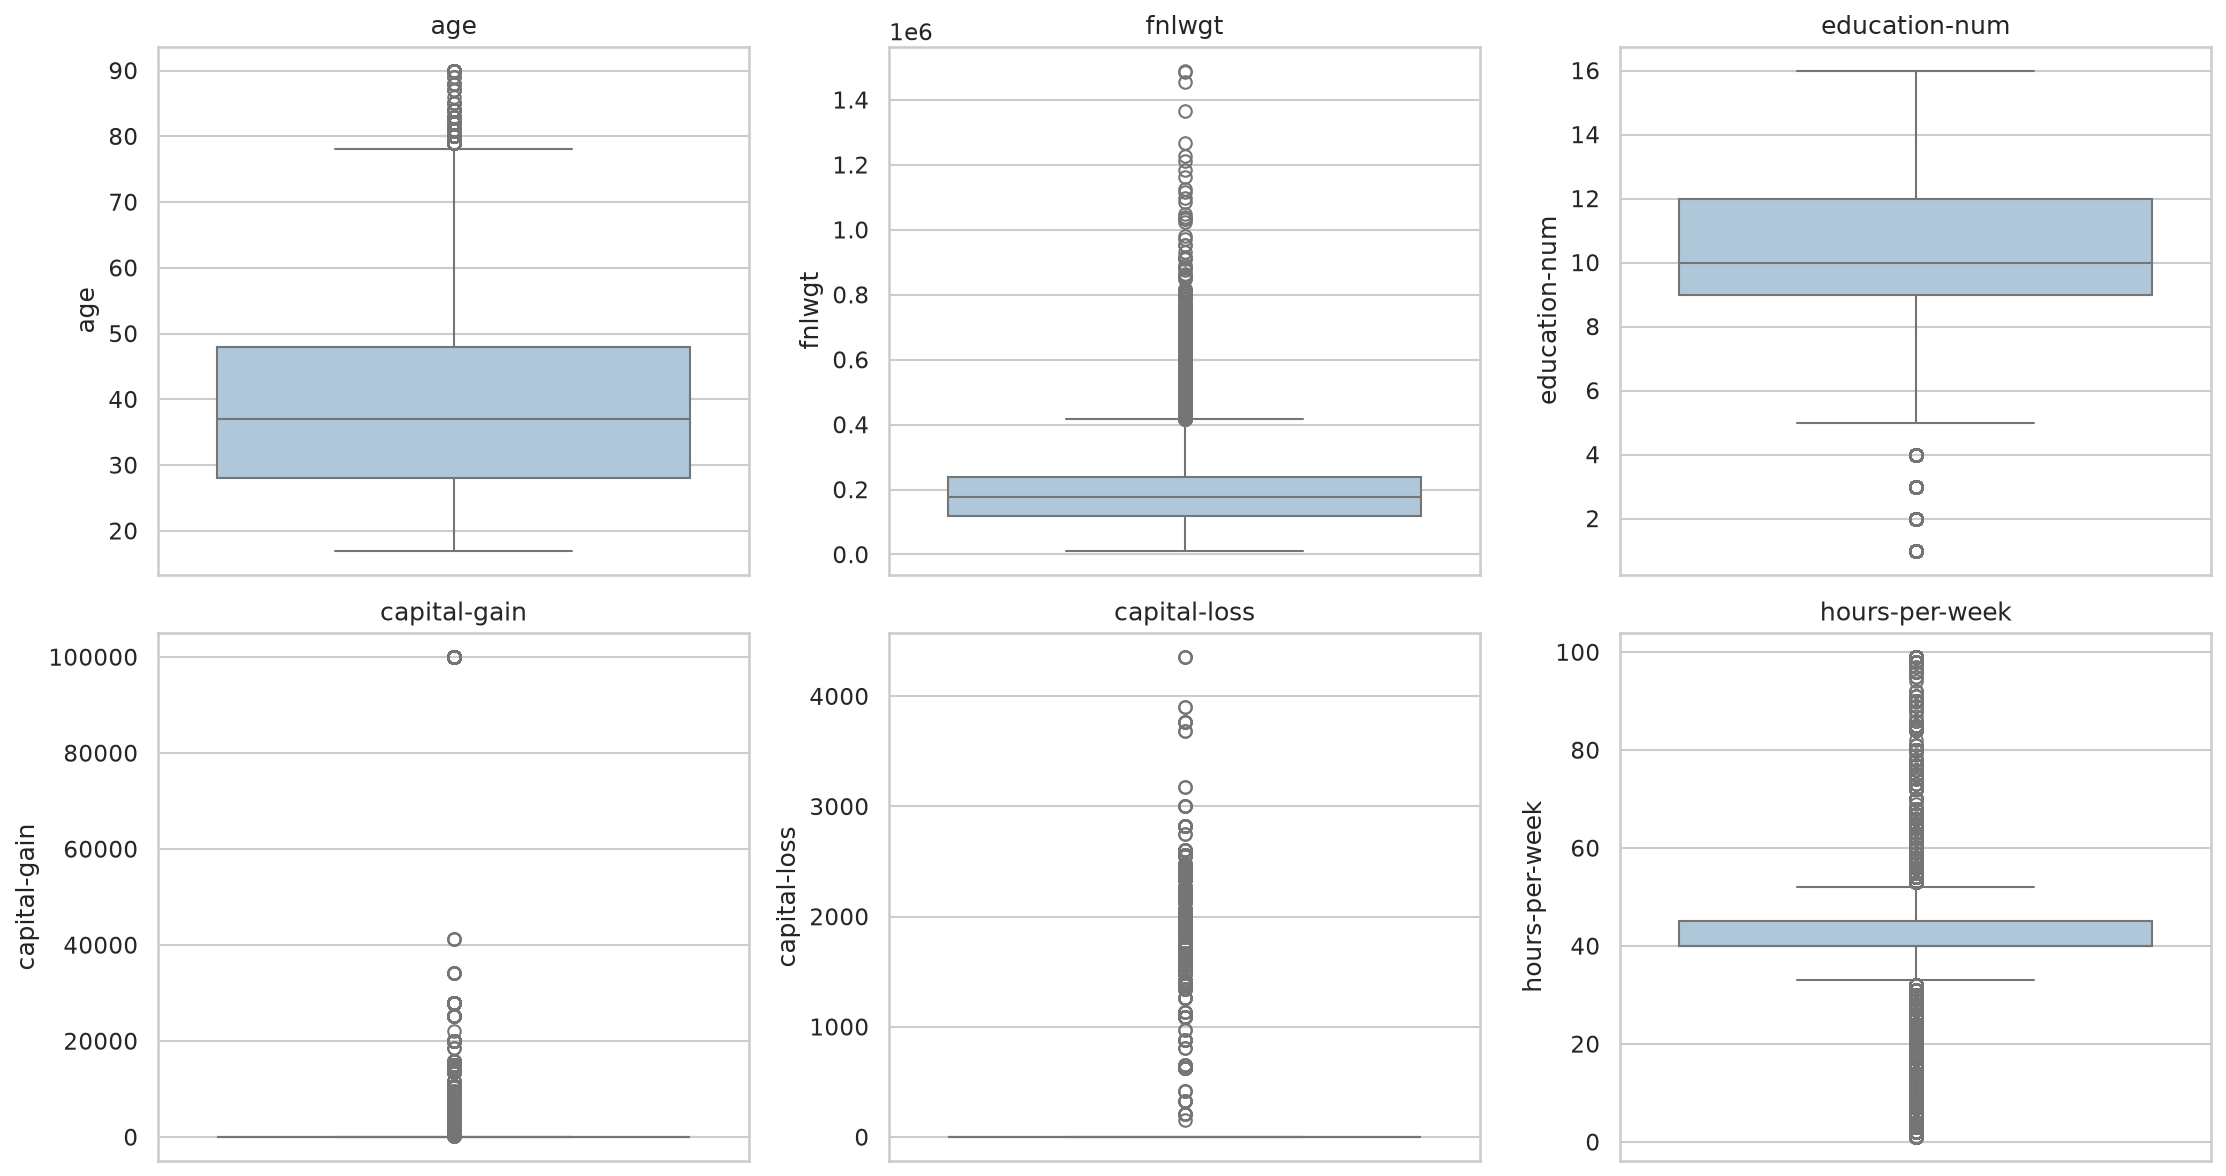

In [9]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

for column, ax in zip(
    numeric_columns,
    axes.flatten()
):
    sns.boxplot(
        data=df,
        y=column,
        ax=ax,
        color="#A8C8DF"
    )

    ax.set_title(column)

plt.tight_layout()
plt.show()

Los diagramas de caja evidencian la presencia de datos atípicos en todas las variables numéricas, especialmente en `capital-gain`, `capital-loss` y `fnlwgt`.

Sin embargo, estos valores no representan necesariamente errores en los datos, sino condiciones particulares de la población estudiada. Por esta razón, se decide no eliminar registros únicamente por su condición de dato atípico, evitando la pérdida de información potencialmente relevante para la clasificación.

Se propone aplicar una transformación logarítmica a las variables de capital y posteriormente escalar las variables numéricas para facilitar el entrenamiento de las redes neuronales.